## 1. Problem
Cardiotocography (CTG) records the fetal heart rate and uterine contractions during pregnancy, and obstetricians use it to judge whether the fetus is in distress. Reading a CTG is partly subjective, so automated decision support could give less experienced staff a second opinion. This project uses the public UCI Cardiotocography dataset (2,126 recordings) to predict the fetal state (normal, suspect or pathological) from the measured CTG features. The main question is: how well do standard classifiers reproduce the experts' consensus label, and how reliably do they detect the rare pathological class compared with a majority-class baseline? The finished project delivers a comparison of at least three models with class-wise metrics and an error analysis. It is a course project and not a diagnostic tool.

## 2. Data

- **Source:** UCI Machine Learning Repository, Cardiotocography, https://archive.ics.uci.edu/dataset/193/cardiotocography
- **Size:** 2,126 recordings, 21 CTG features, expert labels
- **Licence:** CC BY 4.0
- **Loading:** downloaded automatically with the `ucimlrepo` package (dataset id 193) in the Setup section below.

### Data note

1. **Who:** 2,126 fetal CTG recordings. Only pregnancies that were monitored with CTG are included; fetuses that were not monitored could never be in the data. Mother's age, gestational week and other patient details are not included, and it is unknown whether several recordings come from the same mother.
2. **Why:** The recordings were processed automatically (SisPorto software) and classified by experts to develop and evaluate CTG analysis. They were not collected for this prediction task.
3. **When and where:** Portugal. TODO: check the original paper (Ayres de Campos et al., 2000) for years and sites; they are not stated on the UCI page.
4. **Label:** `NSP` = fetal state: 1 Normal, 2 Suspect, 3 Pathological. It is the consensus of three expert obstetricians, so it is the experts' reading of the trace, not a measured clinical outcome. Class shares are 77.8% / 13.9% / 8.3% (1,655 / 295 / 176 recordings, confirmed in Section 4).
5. **Missing:** There are no missing values (0 NaN), so MCAR/MAR/MNAR does not apply directly. Zeros are not hidden missing values either: the columns where 0 would be impossible (`LB`, `ASTV`, `MSTV`, `Width`, `Min`, `Max`, `Mode`, `Mean`, `Median`) contain none. One caveat: 40% of the Pathological recordings have `MLTV` exactly 0 (Normal: 3.9%). We keep them as real values, but cannot tell whether this is a true signal or a software artefact.
6. **Impossible values:** All baseline heart rates (`LB` 106-160 bpm) and percentage columns are plausible. One recording (row 0) is internally inconsistent: `Mean` (137) is larger than `Max` (126); it is handled by a domain rule in Section 5. Zeros in count and rate columns (e.g. decelerations) are legitimate. Also note 13 duplicated rows and an extreme right tail in `FM` (maximum 0.481, 75th percentile 0.003).
7. **Timing / leakage:** All features come from the same recording that the experts read, so the label is closely tied to the features. The 10-class morphologic pattern column `CLASS` comes from the same expert reading and is **excluded** as a feature to avoid leakage.
8. **Consent:** Not stated on the UCI page. The data are public, anonymised numeric features without identifiers. TODO: check the original paper for an ethics statement.

## 3. Setup

Install the one package that is not in Colab by default, import the libraries, fix the random seed and load the data.


In [ ]:
# Import necessary libraries
!pip install -q ucimlrepo

import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

SEED = 42
np.random.seed(SEED)

In [9]:
# Load the dataset from UCI Machine Learning Repository
ctg = fetch_ucirepo(id=193)
X = ctg.data.features
y = ctg.data.targets
print(y.columns.tolist())

df = X.copy()
df["NSP"] = y["NSP"]   # 1 = Normal, 2 = Suspect, 3 = Pathological
# CLASS (10-class morphologic pattern) is deliberately NOT used as a feature (leakage)

# Save a local copy
os.makedirs("data", exist_ok=True)
df.to_csv("data/ctg.csv", index=False)

print(df.shape)
df["NSP"].value_counts().sort_index()

['CLASS', 'NSP']
(2126, 22)


NSP
1    1655
2     295
3     176
Name: count, dtype: int64

## 4. Exploration

Summary statistics, missing and impossible values, class balance, distributions by class and correlations. Every figure is saved to `images/` and commented directly below it.

### 4.1 Summary statistics, missing values and impossible values

In [10]:
features = [c for c in df.columns if c != "NSP"]

print("Rows, columns:", df.shape)
print("Missing values (NaN):", int(df.isna().sum().sum()))
print("Duplicated rows:", int(df.duplicated().sum()))
df[features].describe().T[["min", "25%", "50%", "75%", "max", "mean", "std"]].round(3)

Rows, columns: (2126, 22)
Missing values (NaN): 0
Duplicated rows: 13


,min,25%,50%,75%,max,mean,std
LB,106.0,126.000,133.000,140.000,160.000,133.304,9.841
AC,0.0,0.000,0.002,0.006,0.019,0.003,0.004
FM,0.0,0.000,0.000,0.003,0.481,0.009,0.047
UC,0.0,0.002,0.004,0.007,0.015,0.004,0.003
DL,0.0,0.000,0.000,0.003,0.015,0.002,0.003
DS,0.0,0.000,0.000,0.000,0.001,0.000,0.000
DP,0.0,0.000,0.000,0.000,0.005,0.000,0.001
ASTV,12.0,32.000,49.000,61.000,87.000,46.990,17.193
MSTV,0.2,0.700,1.200,1.700,7.000,1.333,0.883
ALTV,0.0,0.000,0.000,11.000,91.000,9.847,18.397


In [11]:
# Share of recordings that are exactly 0 (only columns that contain zeros)
zero_share = (df[features] == 0).mean().mul(100).round(1)
zero_share = zero_share[zero_share > 0].sort_values(ascending=False)
zero_share.to_frame("% of recordings equal to 0")

,% of recordings equal to 0
DS,99.7
DP,91.6
Nzeros,76.4
FM,61.7
ALTV,58.3
DL,57.9
Tendency,52.4
AC,42.1
UC,15.6
Variance,8.8


In [12]:
# Consistency checks based on what the columns mean (no statistics learned from the data)
stats_cols = ["Mean", "Mode", "Median"]
outside = (df[stats_cols].lt(df["Min"], axis=0) | df[stats_cols].gt(df["Max"], axis=0)).any(axis=1)

checks = pd.Series({
    "Min > Max": int((df["Min"] > df["Max"]).sum()),
    "Width != Max - Min": int((df["Width"] != df["Max"] - df["Min"]).sum()),
    "Mean/Mode/Median outside [Min, Max]": int(outside.sum()),
    "LB outside 100-180 bpm": int(((df["LB"] < 100) | (df["LB"] > 180)).sum()),
    "ASTV or ALTV above 100 %": int(((df["ASTV"] > 100) | (df["ALTV"] > 100)).sum()),
    "Negative values (Tendency excluded)": int((df[features].drop(columns="Tendency") < 0).sum().sum()),
})
display(checks.to_frame("rows breaking the rule"))
df.loc[outside, ["Min", "Max", "Mean", "Mode", "Median", "NSP"]]

,rows breaking the rule
Min > Max,0
Width != Max - Min,0
"Mean/Mode/Median outside [Min, Max]",1
LB outside 100-180 bpm,0
ASTV or ALTV above 100 %,0
Negative values (Tendency excluded),0


,Min,Max,Mean,Mode,Median,NSP
0,62,126,137,120,121,2


**What we see**

- There are **no missing values** (0 NaN) and 13 rows (0.6 %) are exact duplicates. Duplicates are handled in Section 5 *before* the split, so identical rows cannot end up in both the training and the test set.
- **Zeros are not hidden missing values.** The columns where 0 would be physically impossible (`LB`, `ASTV`, `MSTV`, `Width`, `Min`, `Max`, `Mode`, `Mean`, `Median`) contain no zeros. Zeros appear only in rate and count columns, where they mean "no such event in this recording": `DS` 99.7 %, `DP` 91.6 %, `Nzeros` 76.4 %, `FM` 61.7 %, `ALTV` 58.3 %, `DL` 57.9 %, `Tendency` 52.4 % (0 is a valid category) and `AC` 42.1 %.
- **All rules hold except for one recording.** Row 0 has `Mean` = 137 above `Max` = 126, which is impossible. Because this rule needs no statistics it can be applied before the split in Section 5 (set `Mean` to NaN and impute it from the training set). `LB` stays between 106 and 160 bpm, `ASTV` and `ALTV` stay within 0-100 %, and the only negative values are `Tendency` = -1, a valid category.
- **Two things to watch.** `FM` has an extreme right tail (maximum 0.481, 75th percentile 0.003, 39 recordings above 0.1), and several columns are strongly skewed (`Variance`: median 7, maximum 269). We do not delete these rows, but outliers matter for scale-sensitive models such as logistic regression and much less for trees.

### 4.2 Class distribution

,class,n,share %
0,Normal,1655,77.8
1,Suspect,295,13.9
2,Pathological,176,8.3


Majority-class baseline accuracy: 77.8% (Pathological recall = 0)


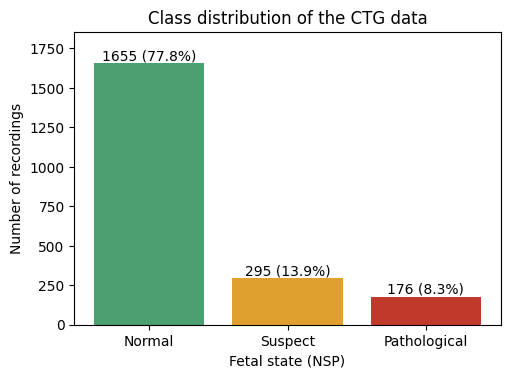

In [13]:
class_names = {1: "Normal", 2: "Suspect", 3: "Pathological"}
class_colors = {1: "#4C9F70", 2: "#E0A030", 3: "#C0392B"}

counts = df["NSP"].value_counts().sort_index()
summary = pd.DataFrame({
    "class": counts.index.map(class_names),
    "n": counts.values,
    "share %": (counts / len(df) * 100).round(1).values,
})
display(summary)
print(f"Majority-class baseline accuracy: {counts.max() / len(df):.1%} (Pathological recall = 0)")

os.makedirs("images", exist_ok=True)
fig, ax = plt.subplots(figsize=(5.5, 3.8))
bars = ax.bar([class_names[k] for k in counts.index], counts.values,
              color=[class_colors[k] for k in counts.index])
for bar, n, s in zip(bars, counts.values, summary["share %"]):
    ax.text(bar.get_x() + bar.get_width() / 2, n + 20, f"{n} ({s}%)", ha="center")
ax.set_xlabel("Fetal state (NSP)")
ax.set_ylabel("Number of recordings")
ax.set_title("Class distribution of the CTG data")
ax.set_ylim(0, counts.max() * 1.12)
plt.savefig("images/eda_class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**What we see.** The classes are strongly imbalanced: Normal 1,655 (77.8 %), Suspect 295 (13.9 %), Pathological 176 (8.3 %). A model that always answers "Normal" is right 77.8 % of the time but never finds a pathological recording (recall 0 %). **Accuracy is therefore not a suitable main metric.** From Section 5 on we use a stratified split and stratified cross-validation, and in Sections 6-7 we report macro-F1 and the recall of the Pathological class, compared with this majority-class baseline. Class weights are tested as a remedy for the imbalance.

### 4.3 Feature distributions by class

In [14]:
key = ["LB", "ASTV", "MSTV", "ALTV", "MLTV", "Variance"]
medians = df.groupby("NSP")[key].median()
medians.index = medians.index.map(class_names)
medians

,LB,ASTV,MSTV,ALTV,MLTV,Variance
NSP,,,,,,
Normal,132.0,41.0,1.3,0.0,8.00,9.0
Suspect,143.0,63.0,0.4,27.0,7.10,1.0
Pathological,132.0,65.0,1.7,0.0,3.25,36.5


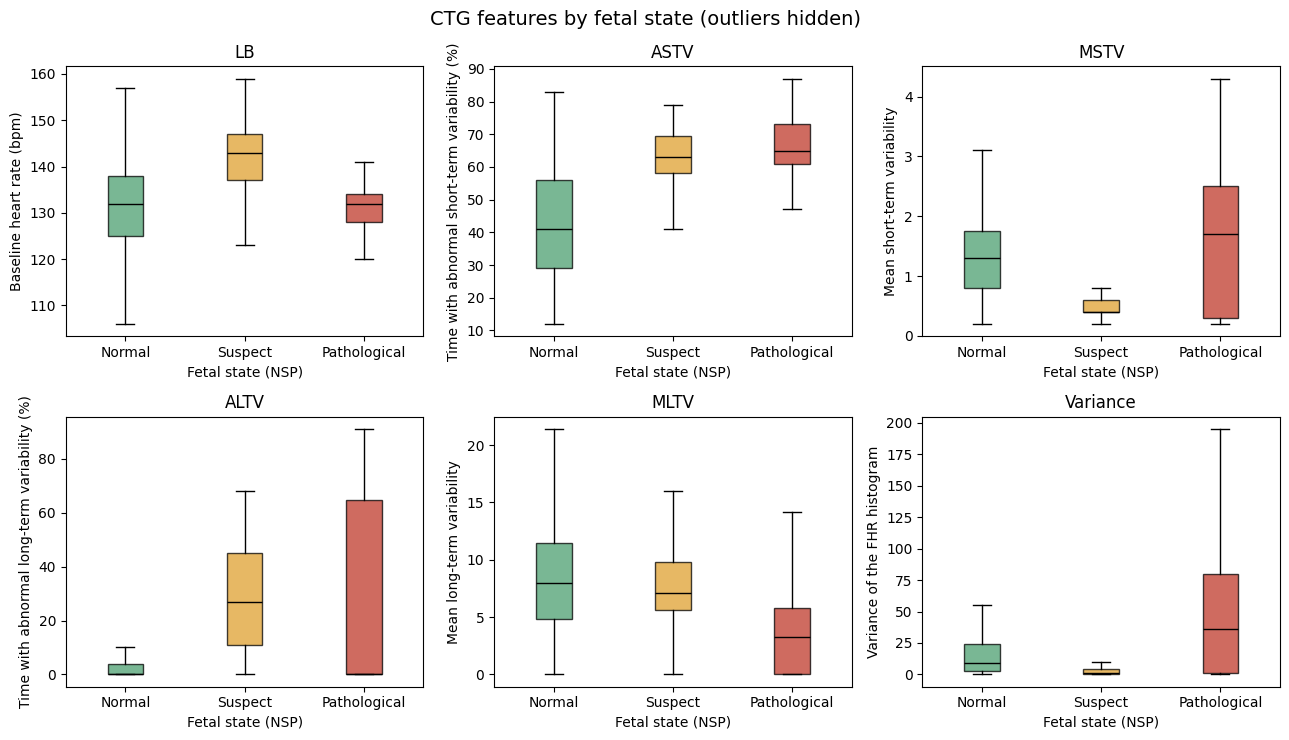

In [15]:
labels = {
    "LB": "Baseline heart rate (bpm)",
    "ASTV": "Time with abnormal short-term variability (%)",
    "MSTV": "Mean short-term variability",
    "ALTV": "Time with abnormal long-term variability (%)",
    "MLTV": "Mean long-term variability",
    "Variance": "Variance of the FHR histogram",
}
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
for ax, col in zip(axes.ravel(), key):
    data = [df.loc[df["NSP"] == k, col] for k in (1, 2, 3)]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False)
    for patch, k in zip(bp["boxes"], (1, 2, 3)):
        patch.set_facecolor(class_colors[k])
        patch.set_alpha(0.75)
    for m in bp["medians"]:
        m.set_color("black")
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels([class_names[k] for k in (1, 2, 3)])
    ax.set_xlabel("Fetal state (NSP)")
    ax.set_ylabel(labels[col])
    ax.set_title(col)
fig.suptitle("CTG features by fetal state (outliers hidden)", fontsize=14)
fig.tight_layout()
plt.savefig("images/eda_boxplots_by_class.png", dpi=150, bbox_inches="tight")
plt.show()

**What we see** (medians Normal / Suspect / Pathological)

- `ASTV` separates Normal from the other two classes: 41 / 63 / 65. A high value is a warning sign, but the Suspect and Pathological boxes overlap, so `ASTV` alone cannot tell those two apart.
- `MSTV` is very low in Suspect recordings (1.3 / 0.4 / 1.7), while Pathological recordings are not lower than Normal.
- `LB` is higher in Suspect recordings (132 / 143 / 132 bpm); Pathological recordings look like Normal ones. So the baseline heart rate helps for the Suspect class only.
- `MLTV` is low in Pathological recordings (8.0 / 7.1 / 3.25) and `Variance` is high (9 / 1 / 36.5).
- **Pathological is the most heterogeneous class.** Its `ALTV` runs from 0 (25th percentile) to about 65 (75th percentile) and its `Variance` from 1 to 80. This suggests that "Pathological" mixes several different patterns, which is a likely reason for errors on this class later.
- `ALTV` has a median of 0 for Normal and for Pathological recordings (the median line sits at the bottom of the box), so boxplots hide what is going on; the next figure shows such zero-heavy features in a better way.

NSP,Normal,Suspect,Pathological
AC,69.8,15.6,17.0
UC,90.6,59.0,68.2
DL,44.3,19.3,59.7
DS,0.1,0.0,3.4
DP,4.2,5.1,53.4
ALTV,33.2,91.9,37.5
MLTV,96.1,99.3,59.7


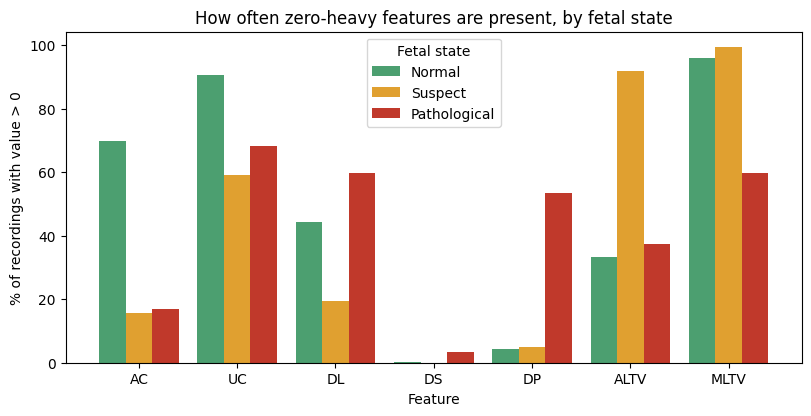

In [16]:
zero_heavy = ["AC", "UC", "DL", "DS", "DP", "ALTV", "MLTV"]
nonzero = (df[zero_heavy] > 0).groupby(df["NSP"]).mean().mul(100).round(1)
nonzero.index = nonzero.index.map(class_names)
display(nonzero.T)

x = np.arange(len(zero_heavy))
w = 0.27
fig, ax = plt.subplots(figsize=(9.5, 4.3))
for i, k in enumerate((1, 2, 3)):
    ax.bar(x + (i - 1) * w, nonzero.loc[class_names[k]], w, label=class_names[k], color=class_colors[k])
ax.set_xticks(x)
ax.set_xticklabels(zero_heavy)
ax.set_xlabel("Feature")
ax.set_ylabel("% of recordings with value > 0")
ax.set_title("How often zero-heavy features are present, by fetal state")
ax.legend(title="Fetal state")
plt.savefig("images/eda_nonzero_share_by_class.png", dpi=150, bbox_inches="tight")
plt.show()

**What we see** (share of recordings with a value above 0, Normal / Suspect / Pathological)

- `AC` (accelerations) is present in 69.8 % of Normal recordings but only 15.6 % / 17.0 % of the others. A missing acceleration is a strong sign against "Normal".
- `DP` (prolonged decelerations) occurs in 4.2 % / 5.1 % / 53.4 %, so it points almost only to Pathological. It is still absent in about 47 % of Pathological recordings, so it is not sufficient on its own. `DS` (severe decelerations) is even rarer: 0.1 % / 0 % / 3.4 %.
- `ALTV` is above 0 in 91.9 % of Suspect recordings but only 33.2 % / 37.5 % of Normal / Pathological ones, which makes it a good marker for the Suspect class.
- `MLTV` is 0 in 40 % of Pathological recordings (Normal 3.9 %, Suspect 0.7 %). We keep these zeros as real values, but it is unclear whether they are a true signal or a software artefact (see data note).
- These are descriptive patterns, not proof of cause.

### 4.4 Correlations

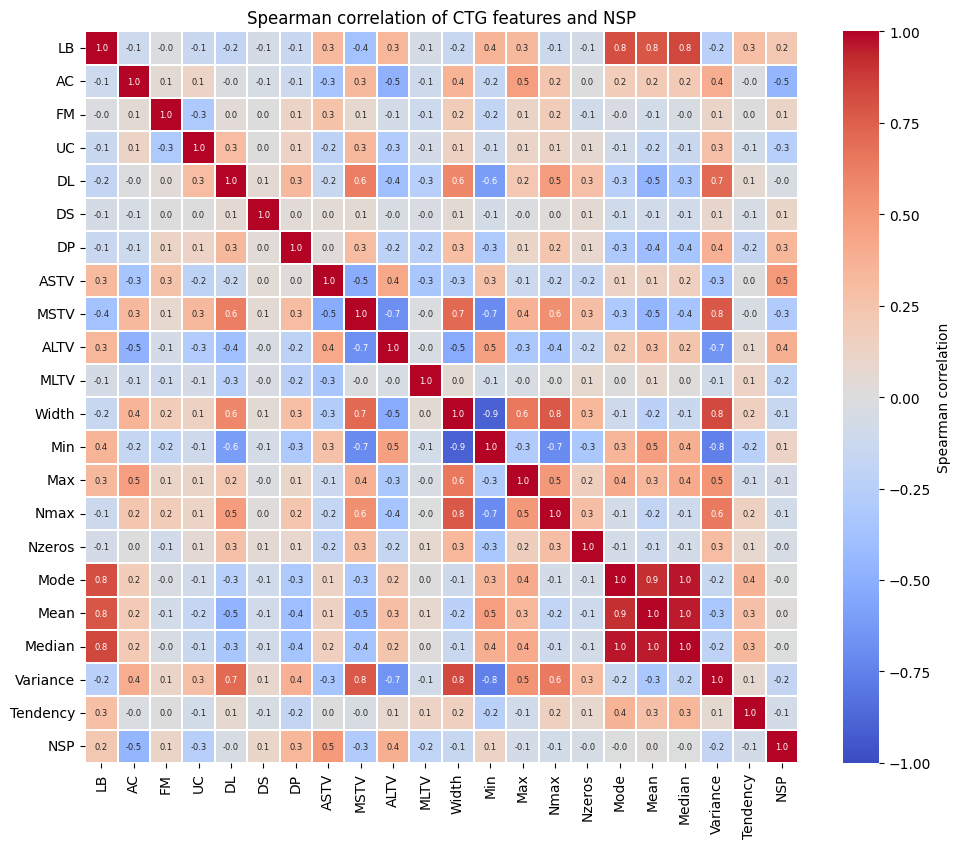

In [17]:
import seaborn as sns

# Spearman: NSP is ordinal (1 < 2 < 3) and many features are skewed or zero-heavy
corr = df.corr(method="spearman")

fig, ax = plt.subplots(figsize=(11.5, 9.5))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, center=0, annot=True, fmt=".1f",
            annot_kws={"size": 6}, linewidths=0.3, cbar_kws={"label": "Spearman correlation"}, ax=ax)
ax.set_title("Spearman correlation of CTG features and NSP")
plt.savefig("images/eda_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
# Strongly related feature pairs (|r| > 0.8)
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs = pairs[pairs.abs() > 0.8].sort_values(key=abs, ascending=False)
display(pairs.round(2).to_frame("Spearman r"))

# Association of each feature with NSP
corr["NSP"].drop("NSP").sort_values(key=abs, ascending=False).round(2).to_frame("Spearman r with NSP")

,,Spearman r
Mode,Median,0.96
Mean,Median,0.96
Mode,Mean,0.91
Width,Min,-0.90
LB,Median,0.84
Width,Variance,0.83
LB,Mode,0.82


,Spearman r with NSP
ASTV,0.50
AC,-0.46
ALTV,0.39
DP,0.34
MSTV,-0.29
UC,-0.26
LB,0.22
MLTV,-0.20
Variance,-0.17
Width,-0.15


**What we see**

- **Redundant features.** `Mean`, `Median` and `Mode` are almost the same information (r = 0.91-0.96); `Min` and `Width` are strongly negatively related (-0.90), `Width` and `Variance` positively (0.83), and `LB` follows `Median` (0.84) and `Mode` (0.82). They are different summaries of the same histogram. Tree-based models cope with this, but logistic regression coefficients can become unstable. We keep all features for now and decide in Sections 5-6.
- **Association with NSP** is strongest for `ASTV` (+0.50), `AC` (-0.46), `ALTV` (+0.39), `DP` (+0.34), `MSTV` (-0.29) and `UC` (-0.26), in line with the plots above. No single feature goes much beyond |0.5|, so no single feature explains the label. `Mean`, `Median` and `Mode` have almost no rank correlation with NSP.
- **Caveat.** Rank correlation assumes the order Normal < Suspect < Pathological. Features that stand out only for the Suspect class (`LB`, `MSTV`) look weaker here than in the boxplots. Correlation is also not causation.

### 4.5 Why `CLASS` is not used as a feature

In [ ]:
# CLASS (10 morphologic patterns) is part of the UCI targets table `y` loaded in Section 3.
leak = pd.crosstab(y["CLASS"], y["NSP"])
leak.index.name = "CLASS (morphologic pattern)"
display(leak)

# How well would CLASS alone reproduce NSP? (majority NSP within each CLASS)
acc_from_class = leak.max(axis=1).sum() / leak.values.sum()
print(f"Accuracy of predicting NSP from CLASS alone: {acc_from_class:.1%}")
print(f"Accuracy of always predicting Normal:        {(y['NSP'] == 1).mean():.1%}")

**Why it is excluded.** `CLASS` is the experts' morphologic reading of the same trace, and `NSP` is derived from that reading. The table above shows how closely the two are tied: using `CLASS` as an input would let a model copy part of the answer instead of learning from the signal features. It would also not be available in practice before an expert has read the trace (timing question in the data note). The loading cell in Section 3 therefore builds `df` from the 21 signal features and `NSP` only.

No other column needs to be removed for leakage: the remaining 21 features are computed from the recording by the SisPorto software. This is consistent with the data note.

## 5. Preparation

We follow the order from Week 4: (1) rules that need no statistics, (2) split first (stratified, fixed seed), (3) learn every statistic on the training set only, (4) apply the same numbers to the test set.

### 5.1 Leakage columns, duplicates and domain rules

`CLASS` is already excluded when `df` is built, so we only check it here. Exact duplicates are removed *before* the split so that identical recordings cannot end up in both the training and the test set. The domain rule needs no statistics: `Mean`, `Mode` and `Median` of the FHR histogram must lie between `Min` and `Max`; impossible values become NaN and are imputed later from the training set.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Leakage: CLASS (or any other label column) must not be in the feature table
assert "CLASS" not in df.columns, "CLASS must not be a feature"
print("Columns in df:", df.shape[1], "(21 signal features + NSP)")

# 2. Exact duplicates are removed BEFORE the split
n_full = int(df.duplicated().sum())
n_feat = int(df.duplicated(subset=features).sum())
print(f"Duplicated rows: {n_full}; duplicated feature rows (label ignored): {n_feat}")
print("If both numbers are equal, no duplicated recording has a different label.")
df_prep = df.drop_duplicates().copy()
print("Rows after removing duplicates:", len(df_prep))

# 3. Domain rule (no statistics): Mean, Mode, Median must lie between Min and Max
for col in ["Mean", "Mode", "Median"]:
    bad = (df_prep[col] < df_prep["Min"]) | (df_prep[col] > df_prep["Max"])
    print(f"{col}: {int(bad.sum())} impossible value(s) set to NaN")
    df_prep.loc[bad, col] = np.nan

na_per_col = df_prep[features].isna().sum()
print("NaN per column after the rule:")
print(na_per_col[na_per_col > 0])

### 5.2 Stratified train/test split

The split is done before any statistic is calculated. It is stratified on `NSP` so that the rare Pathological class appears in both sets in the same proportion, and 25 % of the data is kept for testing so that the test set contains enough Pathological recordings. The seed is fixed for reproducibility.

In [ ]:
X_all = df_prep[features]
y_all = df_prep["NSP"]

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.25, stratify=y_all, random_state=SEED)

split_summary = pd.DataFrame({
    "train n": y_train.value_counts().sort_index(),
    "train %": (y_train.value_counts(normalize=True).sort_index() * 100).round(1),
    "test n": y_test.value_counts().sort_index(),
    "test %": (y_test.value_counts(normalize=True).sort_index() * 100).round(1),
})
split_summary.index = split_summary.index.map(class_names)
display(split_summary)
print("Train / test rows:", len(X_train), "/", len(X_test))

# No recording may appear in both sets
overlap = X_train.drop_duplicates().merge(X_test.drop_duplicates(), how="inner")
print("Feature rows found in both train and test:", len(overlap))

### 5.3 Imputation and scaling (statistics from the training set only)

The one NaN created by the domain rule is filled with the training-set median (robust to the skewed distributions seen in Section 4). Features are then standardised (mean 0, SD 1) because logistic regression is sensitive to scale; the mean and SD are learned on the training set and applied unchanged to the test set. Tree-based models do not need scaling, so the unscaled versions are saved as well.

In [ ]:
# All statistics below are learned on the training set ONLY
train_median = X_train.median()
print("NaN in train / test before imputation:",
      int(X_train.isna().sum().sum()), "/", int(X_test.isna().sum().sum()))

X_train_imp = X_train.fillna(train_median)
X_test_imp = X_test.fillna(train_median)      # same numbers, learned on train
print("NaN left in train / test:",
      int(X_train_imp.isna().sum().sum()), "/", int(X_test_imp.isna().sum().sum()))

scaler = StandardScaler().fit(X_train_imp)
X_train_sc = pd.DataFrame(scaler.transform(X_train_imp), columns=features, index=X_train_imp.index)
X_test_sc = pd.DataFrame(scaler.transform(X_test_imp), columns=features, index=X_test_imp.index)

print("Train: largest |mean| =", round(X_train_sc.mean().abs().max(), 3),
      "| SD min/max =", X_train_sc.std().agg(["min", "max"]).round(2).tolist())
print("Test : largest |mean| =", round(X_test_sc.mean().abs().max(), 3),
      "(not exactly 0, because the test set uses the training statistics)")

### 5.4 Save the processed data

Both sets are saved so that the later sections (and the README) can start from the same split. `train.csv` / `test.csv` are cleaned and imputed but not scaled; the `_scaled` files are the standardised versions.

In [ ]:
os.makedirs("data", exist_ok=True)
X_train_imp.assign(NSP=y_train).to_csv("data/train.csv", index=False)
X_test_imp.assign(NSP=y_test).to_csv("data/test.csv", index=False)
X_train_sc.assign(NSP=y_train).to_csv("data/train_scaled.csv", index=False)
X_test_sc.assign(NSP=y_test).to_csv("data/test_scaled.csv", index=False)
print(sorted(os.listdir("data")))

## 6. Methods

*Which models or analyses, and why. Always include a simple **baseline** (e.g. ZeroR / majority class). If you also used Weka, give the exact classifier, filters and test option, and save the result buffer in `weka/`.*

## 7. Results

*Results on the test set (or cross-validation) with suitable metrics — not only accuracy. Compare with the baseline. Where relevant, report results for subgroups (e.g. sex, age band).*

## 8. Limitations and possible harms

*Which patients may the result not apply to? What could go wrong if someone used it in practice? What would you need to do before any real use?*

## 9. Contributions

*Fill in one row per member. This section must be consistent with the GitHub commit history and with the Contributions section of the report. Update it for the interim report (Week 10) and again for the final.*

| Member | GitHub username | Responsibilities | Notebook sections / files | Approx. share of work |
|---|---|---|---|---|
| <Full name> | @<username> | *e.g. data loading, cleaning* | *e.g. §2, §5, `src/clean.py`* | *e.g. 35%* |
| <Full name> | @<username> |  |  |  |

**What each member did, in their own words (2–4 sentences each):**

- **<Name>:** …
- **<Name>:** …

**Interim (Week 10) → Final:** *what changed in the division of work after the interim report, if anything.*

## 10. External code, libraries and AI tools

| What | Used for | Where |
|---|---|---|
| `ucimlrepo` | downloading the UCI Cardiotocography dataset | §3 |
| pandas, NumPy | data handling and summaries | §3–§5 |
| matplotlib, seaborn | figures | §4 |
| scikit-learn | train/test split, scaling (and models in later sections) | §5–§7 |
| Claude (AI assistant) | TODO: describe exactly what it was used for (e.g. drafting code and text for §1–§5, which we then checked and ran) | TODO: cells / files |

## 11. References

- UCI Machine Learning Repository: Cardiotocography (dataset 193), CC BY 4.0. https://archive.ics.uci.edu/dataset/193/cardiotocography
- Ayres de Campos, D., Bernardes, J., Garrido, A., Marques de Sá, J., Pereira Leite, L. (2000). SisPorto 2.0: A Program for Automated Analysis of Cardiotocograms. *Journal of Maternal-Fetal Medicine* 5:311–318.
- scikit-learn documentation: https://scikit-learn.org/stable/
- TODO: add any further papers, documentation and tutorials you used.

---
*Before submitting: Runtime → Restart and run all · no errors · every `<...>` replaced · notebook saved to the repository · same version uploaded to STIX.*